In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("data/team_22_train.csv")
print(df.head())
print(df.shape)
print(df.describe())
print(df.isnull().count)

   battery_v  temp_c  rings_per_day  wifi_rssi_dbm  age_months  days_left
0      3.593    22.5              9            -66          21       38.6
1      3.950    32.2              0            -61          18      261.2
2      3.721    16.3              3            -75          10       90.6
3      3.372    30.2             23            -58          12        1.9
4      3.900    10.6              5            -75           4      120.9
(2000, 6)
         battery_v       temp_c  rings_per_day  wifi_rssi_dbm   age_months  \
count  2000.000000  2000.000000    2000.000000     2000.00000  2000.000000   
mean      3.766345    27.482150       8.046500      -66.42350    17.759500   
std       0.352124    11.420659       5.642008       12.92953    10.529107   
min       0.000000  -127.000000       0.000000      -88.00000     0.000000   
25%       3.568750    23.500000       4.000000      -77.00000     9.000000   
50%       3.790500    28.000000       7.000000      -67.00000    18.000000   


array([[<Axes: title={'center': 'battery_v'}>,
        <Axes: title={'center': 'temp_c'}>],
       [<Axes: title={'center': 'rings_per_day'}>,
        <Axes: title={'center': 'wifi_rssi_dbm'}>],
       [<Axes: title={'center': 'age_months'}>,
        <Axes: title={'center': 'days_left'}>]], dtype=object)

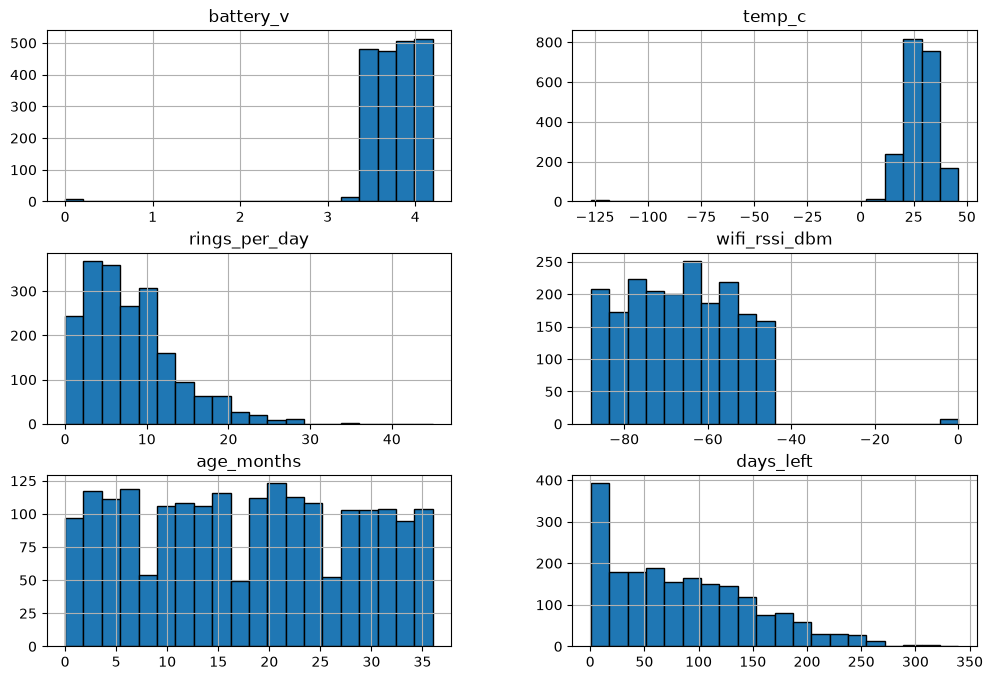

In [4]:
df.hist(
    figsize=(12,8),
    bins = 20,
    edgecolor = "black"
)

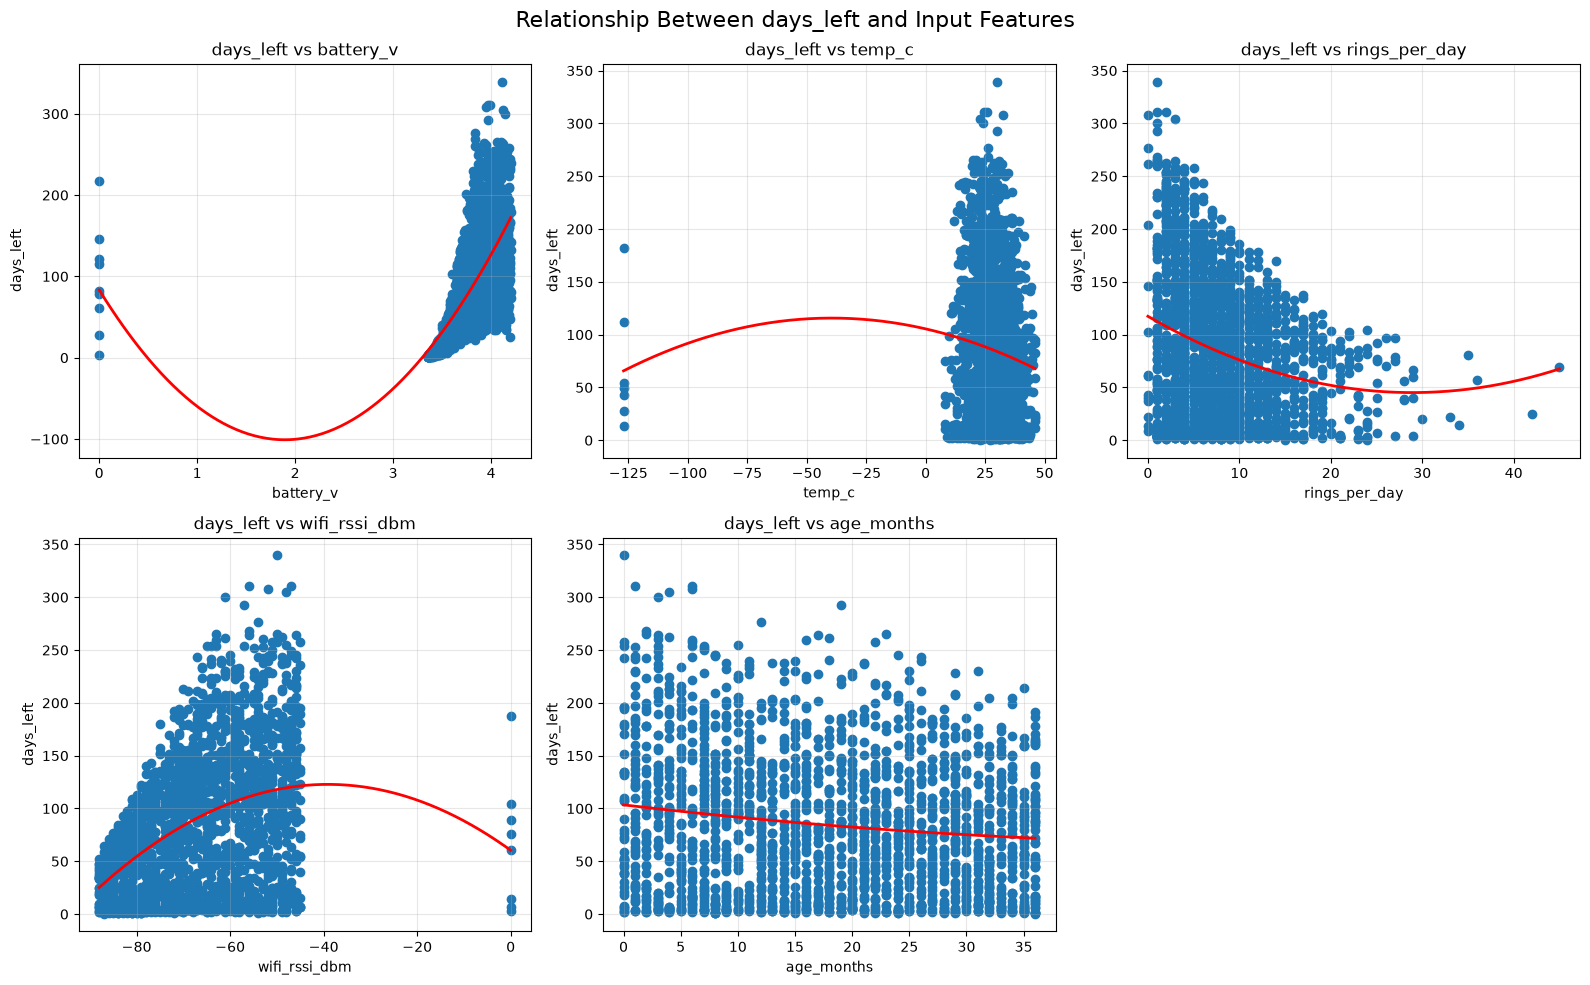

In [5]:

input_features = ['battery_v',  'temp_c',  'rings_per_day',  'wifi_rssi_dbm',  'age_months']
target = "days_left"
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, feature in enumerate(input_features):

    x = df[feature]
    y = df[target]

    # Scatter plot
    axes[i].scatter(x, y,)

    # Add a quadratic trend line to reveal curvature
    coefficients = np.polyfit(x, y, 2)
    polynomial = np.poly1d(coefficients)

    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = polynomial(x_line)

    axes[i].plot(x_line, y_line, color="red", linewidth=2)

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("days_left")
    axes[i].set_title(f"days_left vs {feature}")
    axes[i].grid(True, alpha=0.3)

# Remove unused 6th subplot
fig.delaxes(axes[5])

plt.suptitle("Relationship Between days_left and Input Features", fontsize=16)
plt.tight_layout()
plt.show()

    

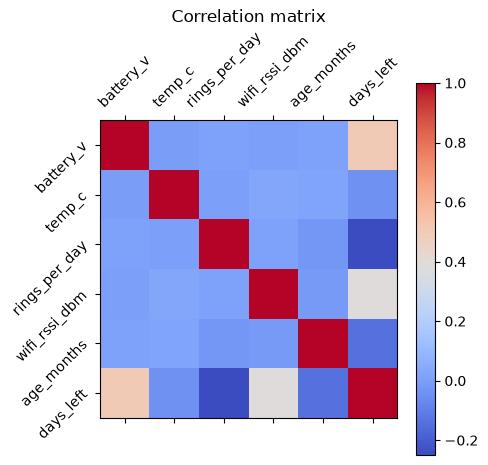

In [6]:
corr_matrix = df.corr()
plt.matshow(corr_matrix,cmap = 'coolwarm')
plt.xticks(range(len(df.columns)),df.columns, rotation = 45)
plt.yticks(range(len(df.columns)),df.columns,rotation=45)
plt.colorbar()
plt.title("Correlation matrix")
plt.show()

In [7]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


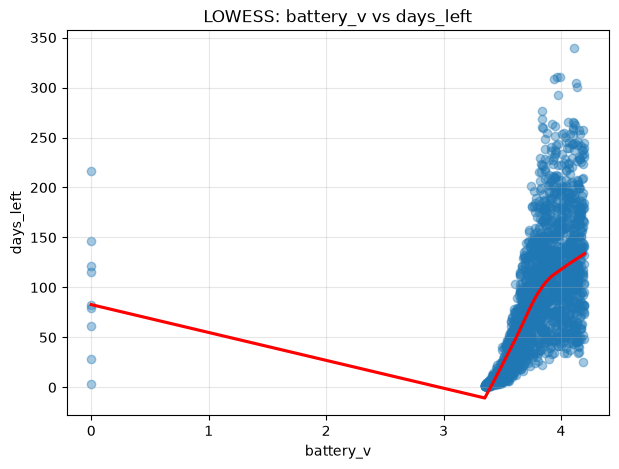

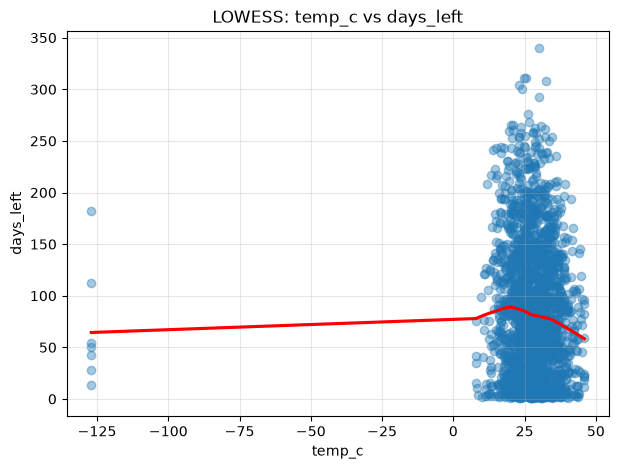

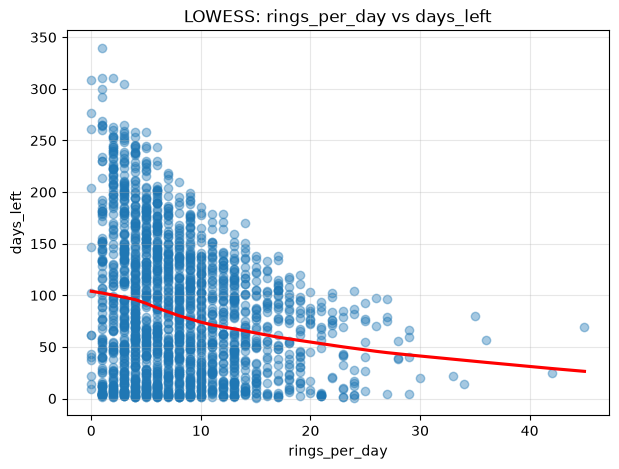

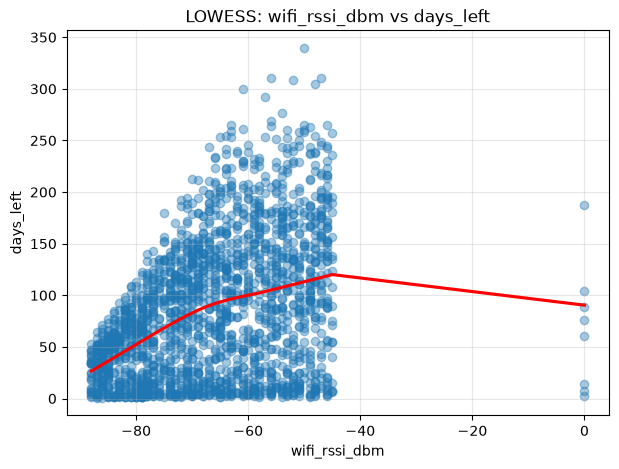

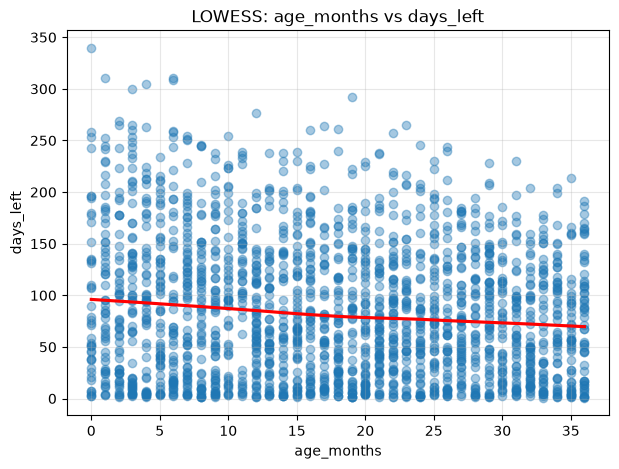

In [8]:
import seaborn as sns
#import matplotlib.pyplot as plt

inputs = [
    "battery_v",
    "temp_c",
    "rings_per_day",
    "wifi_rssi_dbm",
    "age_months"
]

for feature in inputs:

    plt.figure(figsize=(7, 5))

    sns.regplot(
        data=df,
        x=feature,
        y="days_left",
        lowess=True,
        scatter_kws={"alpha": 0.4},
        line_kws={"color": "red"}
    )

    plt.title(f"LOWESS: {feature} vs days_left")
    plt.grid(alpha=0.3)
    plt.show()

In [ ]:
print("Battery voltage:")
print(df[df["battery_v"] < 1]["battery_v"].value_counts())

print("\nTemperature:")
print(df[df["temp_c"] < -75]["temp_c"].value_counts()) #operating in cold regions with -ve temperatures

print("\nWi-Fi signal:")
print(df[df["wifi_rssi_dbm"] >= 0]["wifi_rssi_dbm"].value_counts())

Battery voltage:
battery_v
0.0    9
Name: count, dtype: int64

Temperature:
temp_c
-127.0    7
Name: count, dtype: int64

Wi-Fi signal:
wifi_rssi_dbm
0    8
Name: count, dtype: int64


In [ ]:
print(~np.isfinite(df[input_features]).all(axis=1))

0       False
1       False
2       False
3       False
4       False
        ...  
1995    False
1996    False
1997    False
1998    False
1999    False
Length: 2000, dtype: bool


In [16]:
bad = np.zeros(len(df), dtype=bool)
sensor_cols = [ "battery_v",  "temp_c",  "rings_per_day",  "wifi_rssi_dbm",  "age_months",  "days_left"]
bad |= df["battery_v"] <= 0 #cannot have non positive voltage readings as per given data distribution
bad |= df["temp_c"] < -75 #too negative to make sense in real world domain
bad |= df["wifi_rssi_dbm"] >=0 #impractical or theoretical
bad |= ~np.isfinite(df[sensor_cols]).all(axis=1)
print(f"{len(df)} rows, {bad.sum()} glitch rows dropped")
dfgood = df[~bad]

2000 rows, 24 glitch rows dropped
